# Milestone 3 – Task 7b: SHAP Analysis of the Final XGBoost Model

## Objective

The original SHAP notebook (`milestone3_task7_shap_analysis`) explained **Logistic Regression**, because Logistic Regression looked like the best model in Task 6. That ranking came from an unequal comparison: only Logistic Regression had the `updates` feature. After rerunning every model on equal features, **tuned XGBoost** was selected as the final model (Task 8).

This notebook repeats the SHAP analysis on that final model, once **with** `updates` (Plan B) and once **without** it (Plan A).

It uses the same data, 80/20 stratified split (`random_state=42`), features and XGBoost settings (learning rate 0.1, depth 3, 400 trees) as `scripts/export_artifacts.py`, so the results match the Streamlit app.

**How to read the results.** SHAP shows how much each feature moves the model's prediction. It describes what the model learned from past campaigns. It does not show that changing a feature would cause a different outcome.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

print("xgboost", xgboost.__version__)

xgboost 3.4.1


## 1. Load the data and rebuild the split

Same preparation as Task 2 and `export_artifacts.py`: binary target, state extracted from `location`, 80/20 stratified split.

In [2]:
DATA_PATH = "../data/kickstarter_us_filtered.csv"

df = pd.read_csv(DATA_PATH)
df["success"] = (df["status"] == "successful").astype(int)
df["state"] = df["location"].str.rsplit(",", n=1).str[-1].str.strip()

CAT = ["category", "subcategory", "state"]
NUM_A = ["goal", "duration", "levels"]               # Plan A: without updates
NUM_B = ["goal", "duration", "levels", "updates"]    # Plan B: with updates

train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=df["success"]
)
train, test = df.loc[train_idx], df.loc[test_idx]
print(f"Train: {len(train):,}  Test: {len(test):,}  Success rate: {df['success'].mean():.3f}")

Train: 30,803  Test: 7,701  Success rate: 0.547


## 2. Train the final XGBoost models

Preprocessing is fit on the training data only. The test metrics below should match Task 8 (about 70.3% accuracy and 0.767 ROC-AUC without `updates`; about 81.4% and 0.898 with it). If they do not, check the data file and package versions before trusting the SHAP results.

In [3]:
def make_model(num_features):
    pre = ColumnTransformer([
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ])
    return Pipeline([
        ("preprocessor", pre),
        ("model", XGBClassifier(random_state=42, eval_metric="logloss",
                                learning_rate=0.1, max_depth=3, n_estimators=400)),
    ])

models = {}
for label, num in [("Plan A (without updates)", NUM_A), ("Plan B (with updates)", NUM_B)]:
    m = make_model(num).fit(train[num + CAT], train["success"])
    p = m.predict_proba(test[num + CAT])[:, 1]
    print(f"{label}: accuracy = {accuracy_score(test['success'], p > 0.5):.3f}, "
          f"ROC-AUC = {roc_auc_score(test['success'], p):.3f}")
    models[label] = (m, num)

Plan A (without updates): accuracy = 0.703, ROC-AUC = 0.767


Plan B (with updates): accuracy = 0.814, ROC-AUC = 0.898


## 3. Compute SHAP values and group them by original feature

XGBoost computes exact TreeSHAP values itself (`pred_contribs=True`), using the same algorithm as `shap.TreeExplainer`. Category, subcategory and state are one-hot encoded into many columns, so each column's SHAP value is **summed back to its original feature**. This makes the ranking comparable across features.

**Keep the input sparse.** The pipeline gives XGBoost a sparse matrix, where blank entries are treated as *missing*. Converting it to a dense array turns those blanks into real zeros, which sends campaigns down different branches and changes the predictions. So SHAP is computed on the sparse matrix, exactly as the model sees it.

SHAP is computed on a random sample of 2,000 test campaigns. A check confirms the SHAP values plus the base value reproduce the **pipeline's** own predicted probabilities.

In [4]:
def group_of(name):
    if name.startswith("num__"):
        return name[len("num__"):]
    if name.startswith("cat__subcategory_"):
        return "subcategory"
    if name.startswith("cat__category_"):
        return "category"
    return "state"

def grouped_shap(model, num, n=2000):
    pre, clf = model.named_steps["preprocessor"], model.named_steps["model"]
    sample = test[num + CAT].sample(min(n, len(test)), random_state=0)
    Xt = pre.transform(sample)          # keep the sparse form the pipeline gives the model
    names = pre.get_feature_names_out()

    contribs = clf.get_booster().predict(xgboost.DMatrix(Xt), pred_contribs=True)
    sv, base = contribs[:, :-1], contribs[:, -1]

    # Check: base value + SHAP values must equal the pipeline's own log-odds
    p = model.predict_proba(sample)[:, 1]
    gap = np.abs(sv.sum(axis=1) + base - np.log(p / (1 - p))).max()
    assert gap < 1e-3, f"SHAP does not match the model's predictions (gap {gap:.4f})"

    groups = np.array([group_of(nm) for nm in names])
    grouped = pd.DataFrame(
        {g: sv[:, groups == g].sum(axis=1) for g in pd.unique(groups)}
    )
    return sample.reset_index(drop=True), grouped

results = {}
for label, (m, num) in models.items():
    sample, grouped = grouped_shap(m, num)
    results[label] = (sample, grouped, num)
    print(f"{label}: SHAP computed for {len(sample):,} campaigns, additivity check passed")

Plan A (without updates): SHAP computed for 2,000 campaigns, additivity check passed


Plan B (with updates): SHAP computed for 2,000 campaigns, additivity check passed


## 4. Which features matter most?

Importance is the **mean absolute SHAP value** per original feature, in log-odds units. A larger value means the feature moves predictions more, on average, in either direction.

In [5]:
importance = {}
for label, (sample, grouped, num) in results.items():
    imp = grouped.abs().mean().sort_values(ascending=False)
    importance[label] = imp
    print(label)
    display(imp.round(3).rename("mean |SHAP|").to_frame())

Plan A (without updates)


,mean |SHAP|
goal,0.603
levels,0.440
state,0.226
category,0.216
duration,0.198
subcategory,0.161


Plan B (with updates)


,mean |SHAP|
updates,1.476
goal,0.849
category,0.392
state,0.225
duration,0.224
levels,0.186
subcategory,0.139


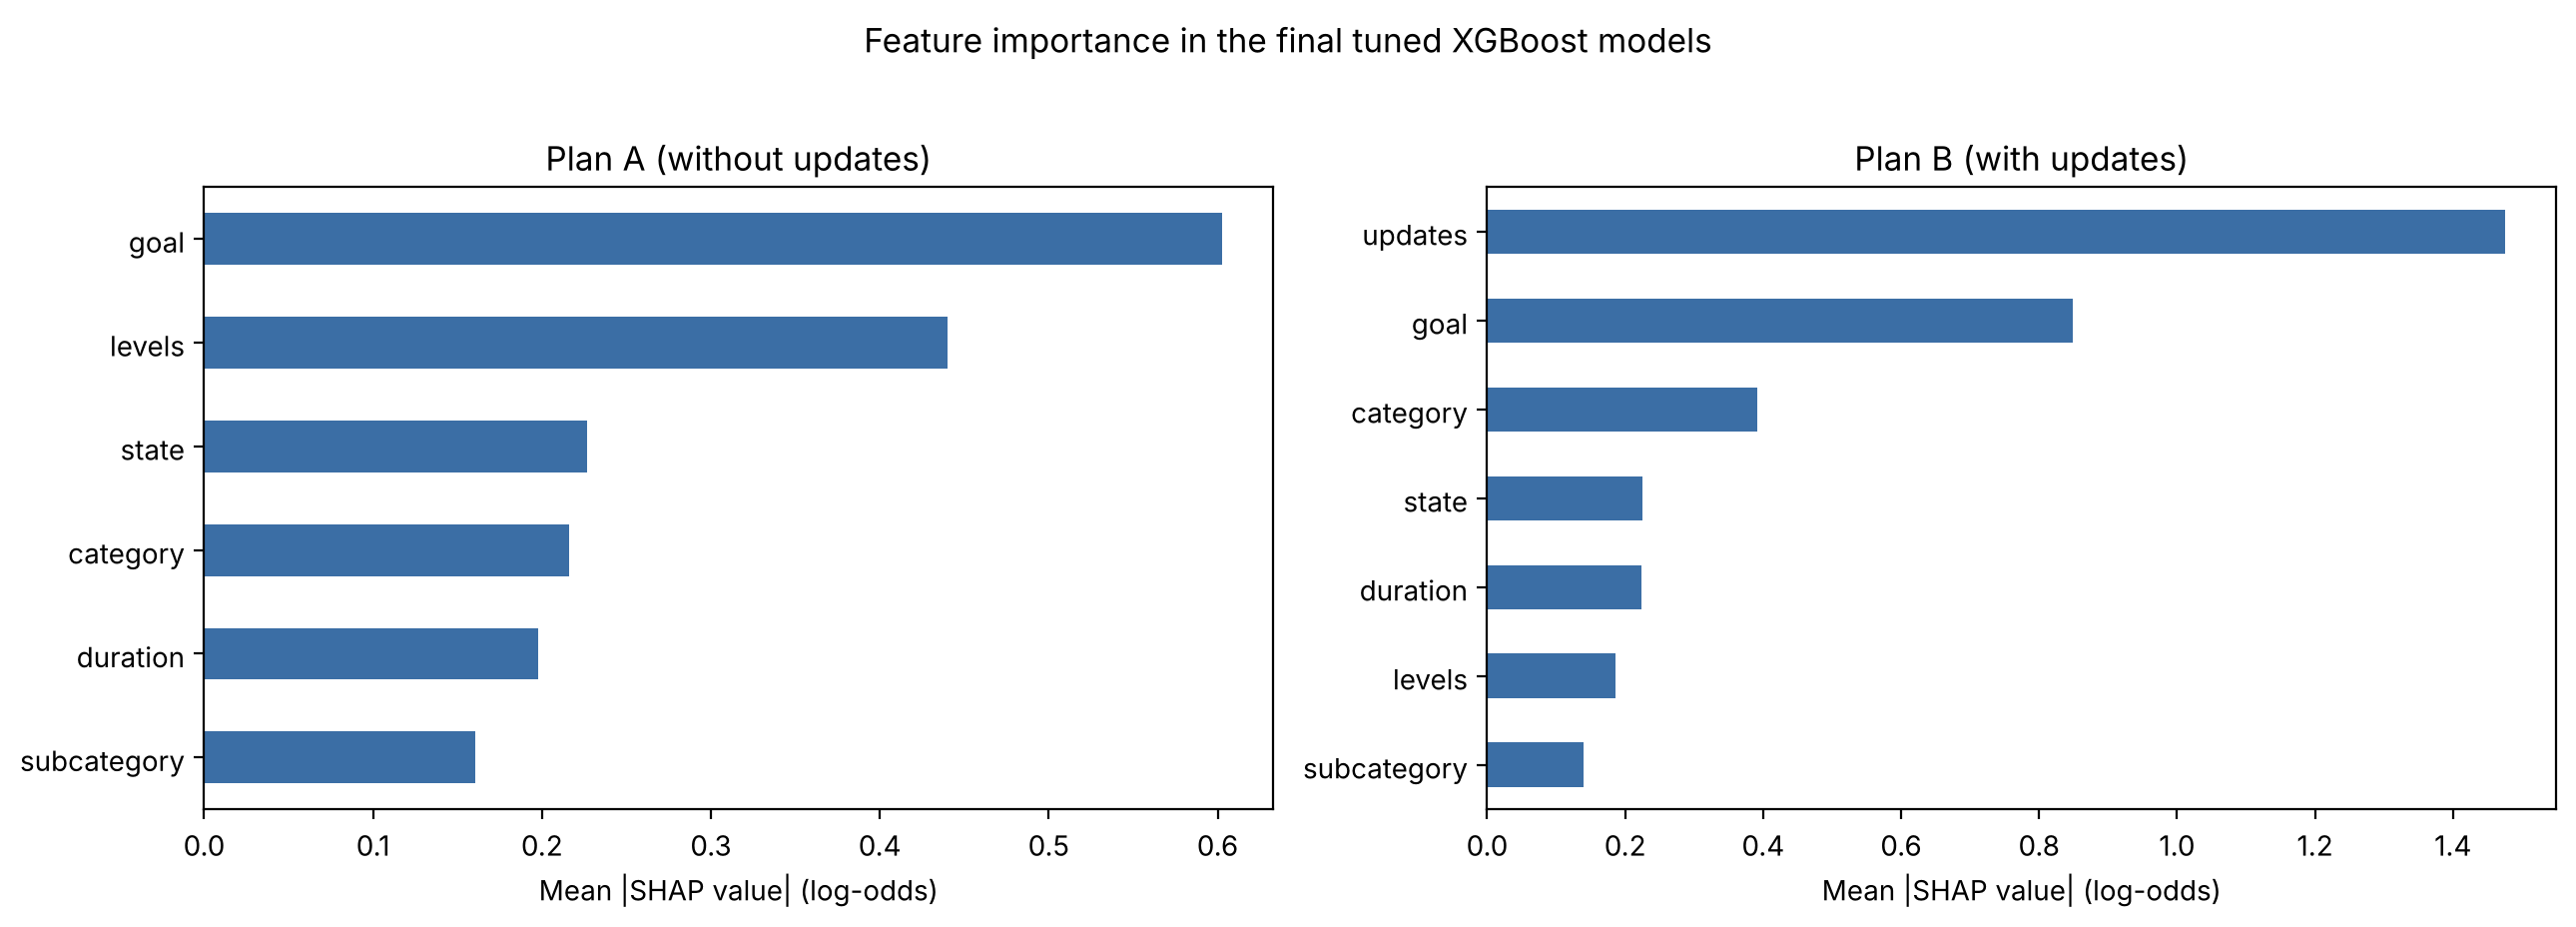

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (label, imp) in zip(axes, importance.items()):
    imp.sort_values().plot(kind="barh", ax=ax, color="#3b6ea5")
    ax.set_title(label)
    ax.set_xlabel("Mean |SHAP value| (log-odds)")
plt.suptitle("Feature importance in the final tuned XGBoost models", y=1.02)
plt.tight_layout()
plt.show()

## 5. Which direction does each numeric feature push?

For each numeric feature, the Spearman correlation between the feature's value and its SHAP value shows the general direction: positive means higher values go with a higher predicted chance of success.

In [7]:
rows = []
for label, (sample, grouped, num) in results.items():
    for f in num:
        rho = pd.Series(sample[f].values).corr(pd.Series(grouped[f].values), method="spearman")
        direction = ("higher value -> higher chance" if rho > 0.1
                     else "higher value -> lower chance" if rho < -0.1 else "mixed")
        rows.append({"model": label, "feature": f, "spearman": round(rho, 2), "direction": direction})
pd.DataFrame(rows)

,model,feature,spearman,direction
0,Plan A (without updates),goal,-0.99,higher value -> lower chance
1,Plan A (without updates),duration,-0.63,higher value -> lower chance
2,Plan A (without updates),levels,0.99,higher value -> higher chance
3,Plan B (with updates),goal,-0.99,higher value -> lower chance
4,Plan B (with updates),duration,-0.83,higher value -> lower chance
5,Plan B (with updates),levels,0.90,higher value -> higher chance
6,Plan B (with updates),updates,0.98,higher value -> higher chance


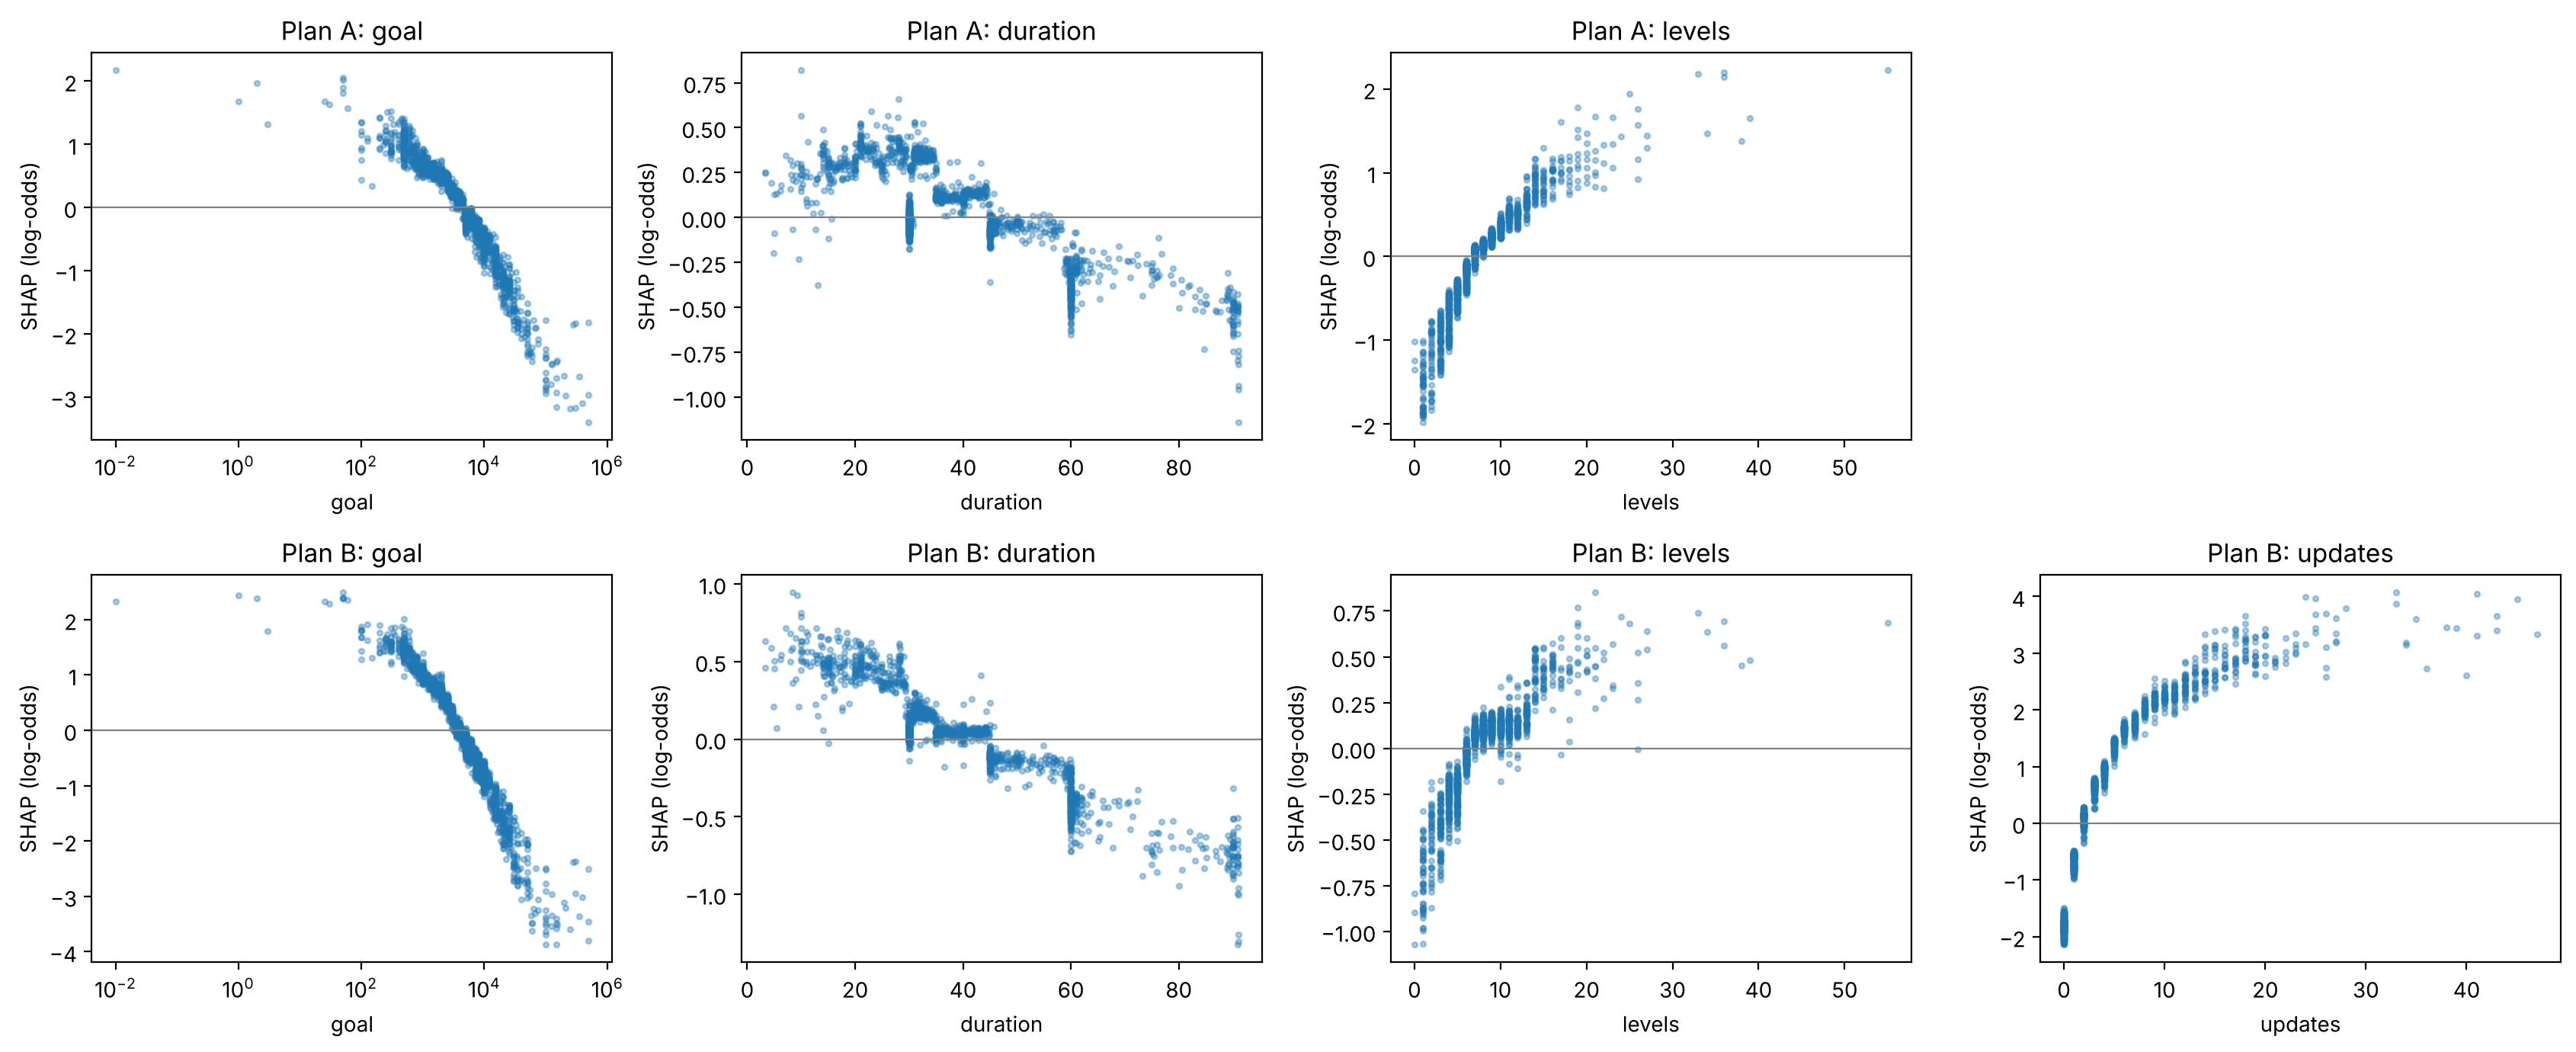

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for r, (label, (sample, grouped, num)) in enumerate(results.items()):
    for c in range(4):
        ax = axes[r, c]
        if c < len(num):
            f = num[c]
            ax.scatter(sample[f], grouped[f], s=6, alpha=0.35)
            ax.axhline(0, color="grey", lw=0.8)
            if f == "goal":
                ax.set_xscale("log")
            ax.set_xlabel(f)
            ax.set_ylabel("SHAP (log-odds)")
            ax.set_title(f"{label.split(' (')[0]}: {f}")
        else:
            ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Check against the Streamlit app's numbers (optional)

`scripts/export_artifacts.py` saves its own driver ranking to `models/lookups.json`. If you have run that script, the ranking below should match the one above.

In [9]:
import json
from pathlib import Path

lookup_path = Path("../models/lookups.json")
if lookup_path.exists():
    saved = json.loads(lookup_path.read_text())["driver_importance"]
    for key, label in [("plan_a", "Plan A (without updates)"), ("plan_b", "Plan B (with updates)")]:
        print(key, "saved ranking :", [d["driver"] for d in saved[key]])
        print(key, "this notebook :", [str(f) for f in importance[label].index])
else:
    print("models/lookups.json not found. Run `python scripts/export_artifacts.py` from the repo root to compare.")

plan_a saved ranking : ['goal', 'levels', 'state', 'category', 'duration', 'subcategory']
plan_a this notebook : ['goal', 'levels', 'state', 'category', 'duration', 'subcategory']
plan_b saved ranking : ['updates', 'goal', 'category', 'state', 'duration', 'levels', 'subcategory']
plan_b this notebook : ['updates', 'goal', 'category', 'state', 'duration', 'levels', 'subcategory']


## 7. Findings

Results on 2,000 test campaigns (mean |SHAP| in log-odds). Test metrics match Task 8: 70.3% accuracy / 0.767 ROC-AUC without `updates`, 81.4% / 0.898 with it. The ranking matches the one saved by `scripts/export_artifacts.py` for the Streamlit app.

- **With `updates` (Plan B):** `updates` has by far the largest influence (1.48), followed by funding goal (0.85) and category (0.39). State, duration, reward levels and subcategory follow at about 0.14–0.23; state and duration are effectively tied.
- **Without `updates` (Plan A):** funding goal (0.60) and reward levels (0.44) lead clearly, followed by state (0.23), category (0.22), duration (0.20) and subcategory (0.16).
- **Direction:** in both models, lower goals, shorter campaigns and more reward levels go with a higher predicted chance of success, and more updates go with a higher chance in Plan B. This matches the exploratory analysis.
- **Compared with the Logistic Regression SHAP result** in Task 7 (`updates`, funding goal, then campaign duration): the top two features are the same. In the final XGBoost model, category ranks third and duration ranks lower. Reward levels matter much more once `updates` is removed.

**Limitations.** SHAP explains this model's behavior on historical data. It does not show that changing a feature causes a different outcome, and it inherits the caveat about `updates` (it may include post-launch activity, so its large effect should be read carefully). Features with similar importance (for example state and duration in Plan B) should not be ranked against each other with confidence.